# 05 · BGE-small student: alignment + contrastive refinement, full fine-tune (DDP, 2 GPUs)
A second, much smaller student: `BAAI/bge-small-en-v1.5` (BERT, 12 layers, hidden 384, 33M params), CLS pooling,
right padding. A linear head 384→256 maps it into the teacher index space. **Every weight trains** (no LoRA, no
pruning), in two stages:
1. **Align**: put the student's query vector on the teacher's vector of the same query,
   L2 = ||s − t||² = 2 − 2·cos (as in `02`).
2. **Contrastive refinement**: from stage 1, rank the labelled positive above the batch's other teacher docs
   (as in `03`): L = CE(logits / tau, own positive) + l2_weight · L2. Documents stay the frozen teacher `corpus.npy`.

Each stage is its own checkpoint dir (`bge_aligned/`, `bge_aligned_cr/`, each with `final/`) and its own row.
Re-running resumes and a finished stage is skipped.

Input: `01`. Output (attach to `04`): `runs/<mode>/{bge_aligned, bge_aligned_cr}/`, `runs/<mode>/metrics.json`.

In [1]:
from kaggle_secrets import UserSecretsClient
secret_label = "HF_TOKEN"
secret_value = UserSecretsClient().get_secret(secret_label)

In [2]:
# setup: clone/pull the repo on Kaggle, put it on sys.path, install what's missing (re-run to pull latest code)
import os, sys, importlib.util
REPO_URL = "https://github.com/pyther-hub/hlm-poc.git"
ON_KAGGLE = os.path.exists("/kaggle/working")
REPO = "/kaggle/working/hlm-poc" if ON_KAGGLE else os.path.abspath("..")
if ON_KAGGLE:
    if not os.path.exists(REPO):
        !git clone -q {REPO_URL} {REPO}
    else:
        !git -C {REPO} pull -q
sys.path.insert(0, REPO)

# HF token (higher rate limits, faster downloads). Kaggle: Add-ons -> Secrets -> add "HF_TOKEN", attach to notebook.
# Spawned workers inherit os.environ. Locally: export HF_TOKEN or `huggingface-cli login`.
if ON_KAGGLE and "HF_TOKEN" not in os.environ:
    try:
        from kaggle_secrets import UserSecretsClient
        os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception as e:
        print(f"HF_TOKEN secret not found ({type(e).__name__}): downloads stay unauthenticated")

import transformers
from packaging.version import Version
if Version(transformers.__version__) < Version("4.56"):  # Qwen3 + the dtype= kwarg
    !pip install -q -U "transformers>=4.56"
    print("transformers upgraded: restart the kernel, then re-run this cell")
for pkg in ("datasets", "pyarrow", "accelerate"):
    if importlib.util.find_spec(pkg) is None:
        !pip install -q {pkg}



## Control panel

In [3]:
import os
import shutil
import torch
from model import get_device
from teacher import TEACHER_DEFAULTS as T

DEBUG = False    # use the same value as in 01
NPROCS = 2

# --- paths. On Kaggle, earlier notebooks' outputs are attached as inputs (read only); set the slugs to yours.
#     Off Kaggle everything lives under the repo, so every IN_* is the same dir.
ROOT = "/kaggle/working" if ON_KAGGLE else REPO
MODE = "debug" if DEBUG else "full"
KAGGLE_IN = "/kaggle/input/datasets/tensorpanda231"
IN_01 = f"{KAGGLE_IN}/corpus-teacher-embd" if ON_KAGGLE else REPO
DATA_PATH = f"{IN_01}/cache/{MODE}/data.json"
EMB_DIR = f"{IN_01}/cache/{MODE}/emb/teacher"
RUN_DIR = f"{ROOT}/runs/{MODE}"
PREV_METRICS = f"{IN_01}/runs/{MODE}/metrics.json"

STUDENT = "BAAI/bge-small-en-v1.5"
# BGE's optional retrieval instruction is "Represent this sentence for searching relevant passages: "; off by
# default to match the other students. Must be the same in ALIGN, REFINE and EVAL.
QUERY_PREFIX = ""

# --- stage 1: alignment, full fine-tune (align.ALIGN_DEFAULTS; unknown keys raise)
ALIGN = dict(model=STUDENT,
             full=True,                           # every base weight + head trains; no LoRA (lora_* unused)
             dim=T["dim"],                        # head output = teacher index dim
             query_prefix=QUERY_PREFIX, max_query_len=32,
             loss="l2", loss_kwargs={},           # ||s - t||^2 = 2 - 2 cos between unit vectors
             lr=1e-4,                             # all base weights; the usual full-FT range for a 33M BERT is 2e-5..1e-4
             head_lr=3e-4,                        # the head starts random
             weight_decay=0.0, warmup_ratio=0.05,
             epochs=20, batch_size=128*8,            # per GPU; global batch = batch_size * NPROCS
             grad_clip=1.0, amp=True, seed=0,
             log_every=20, eval_every=100, save_every=400, keep_last=2,
             data_path=DATA_PATH, teacher_emb_dir=EMB_DIR, out_dir=f"{RUN_DIR}/bge_aligned")

# --- stage 2: contrastive refinement of every weight (refine.REFINE_DEFAULTS; init_adapter / out_dir set below)
REFINE = dict(dim=T["dim"], query_prefix=QUERY_PREFIX, max_query_len=32,
              tau=0.05,                            # temperature
              margin=0.1,                          # mask negatives with s > s(q, d+) + margin (likely false negatives)
              n_neg=1,                             # negatives per query: 1 = stored one, k > 1 adds k-1 teacher-mined
              l2_weight=0.1,                       # keeps the student near the teacher query space; 0 = pure L_CR
              lr=3e-5, head_lr=3e-5, weight_decay=0.05, warmup_ratio=0.05,
              epochs=20, batch_size=128*8,            # queries per GPU; docs per step = (1 + n_neg) * batch_size * NPROCS
              grad_clip=1.0, amp=True, seed=0,
              log_every=20, eval_every=100, save_every=500, keep_last=2,
              data_path=DATA_PATH, teacher_emb_dir=EMB_DIR)

# --- evaluation (evaluation.evaluate_model kwargs): student queries vs the frozen teacher corpus, top 100
EVAL = dict(splits=("val", "test"), dim=T["dim"], max_query_len=32, query_prefix=QUERY_PREFIX, device=get_device(),
            dtype="fp16")
LATENCY = dict(n_queries=2000, batch_sizes=(1, 32))

if DEBUG:
    for cfg in (ALIGN, REFINE):
        cfg.update(log_every=5, eval_every=20, save_every=20)
    LATENCY.update(n_queries=200)

## 1 · Check inputs
Teacher vectors valid (finite, unit norm, `data.json` order) for the corpus, val/test and the alignment queries.

In [4]:
from data import load_emb, load_json
from evaluation import check_emb, load_index

# rows accumulate across notebooks: start from the previous notebook's metrics.json (copied once)
os.makedirs(RUN_DIR, exist_ok=True)
if not os.path.exists(f"{RUN_DIR}/metrics.json") and os.path.exists(PREV_METRICS):
    shutil.copy(PREV_METRICS, f"{RUN_DIR}/metrics.json")
data = load_json(DATA_PATH)
index = load_index(data, EMB_DIR, ("val", "test"))   # (teacher docs, {split: teacher queries})
emb, ids = load_emb(EMB_DIR, "align")
check_emb(emb, ids, data["align"]["ids"], "align")
assert set(data["train"]["ids"]) <= set(data["align"]["ids"]), "train queries need teacher vectors (align set)"
print(f"align {emb.shape}: {len(ids) // (ALIGN['batch_size'] * NPROCS)} align steps, "
      f"{len(data['train']['ids']) // (REFINE['batch_size'] * NPROCS)} refine steps")

[eval] index ok: corpus (299985, 256), val (5000, 256), test (5000, 256)
align (200000, 256): 97 align steps, 43 refine steps


## 2 · Align (full fine-tune)
Rank r takes its slice of every global batch; DDP averages the gradients of every weight. Val L2 / cos / nDCG@10 are
logged every `eval_every` steps.

In [5]:
from align import align_main
from run_exp import train_once

runs = {"bge_aligned": train_once(align_main, ALIGN, NPROCS)}

[rank1] joined process group on cuda:1 (14.5/14.6 GB free)
[rank0] joined process group on cuda:0 (14.5/14.6 GB free)
[rank1] waiting for rank 0 to load the model[rank0] loading BAAI/bge-small-en-v1.5



Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2793.65it/s]
/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
[rank0]:[W1030 21:05:04.500669336 ProcessGroupNCCL.cpp:5188] Guessing device ID based on global rank. This can cause a hang if rank to GPU mapping is heterogeneous. You can specify device_id in init_process_group()


[rank0] model loaded on cuda:0 (14.3/14.6 GB free)
[rank1] loading BAAI/bge-small-en-v1.5
[align] 200000 examples, global batch 2048, 97 steps/epoch, 1940 steps, 33.31M trainable params
[rank0] wrapping in DDP (14.2/14.6 GB free)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2883.64it/s]


[rank1] model loaded on cuda:1 (14.2/14.6 GB free)
[rank1] wrapping in DDP (14.2/14.6 GB free)
[rank1] training from step 0 of 1940
[rank0] training from step 0 of 1940


/kaggle/working/hlm-poc/align.py:214: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  means = {("train_loss" if k == "loss" else k): reduce_mean(float(v), device) for k, v in parts.items()}
/kaggle/working/hlm-poc/align.py:214: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  means = {("train_loss" if k == "loss" else k): reduce_mean(float(v), device) for k, v in parts.items()}


[align] step 20  epoch 0  train_loss 1.724  lr 2.165e-05  min 0.1781
[align] step 40  epoch 0  train_loss 1.314  lr 4.227e-05  min 0.3429
[align] step 60  epoch 0  train_loss 1.126  lr 6.289e-05  min 0.5076
[align] step 80  epoch 0  train_loss 0.9875  lr 8.351e-05  min 0.6778
[align] step 100  epoch 1  train_loss 0.8955  lr 0.0001  min 0.8469
[rank1] step 100: waiting for rank 0 to evaluate
[align] step 100  val_loss 0.8552  val_ndcg@10 0.02579  val_recall@10 0.05095  val_cos 0.5724
[align] step 120  epoch 1  train_loss 0.8267  lr 9.996e-05  min 1.05
[align] step 140  epoch 1  train_loss 0.7861  lr 9.987e-05  min 1.237
[align] step 160  epoch 1  train_loss 0.755  lr 9.971e-05  min 1.432
[align] step 180  epoch 1  train_loss 0.7232  lr 9.95e-05  min 1.612
[rank1] step 200: waiting for rank 0 to evaluate
[align] step 200  epoch 2  train_loss 0.6941  lr 9.923e-05  min 1.781
[align] step 200  val_loss 0.6562  val_ndcg@10 0.182  val_recall@10 0.2978  val_cos 0.6719
[align] step 220  epoch 2

## 3 · Contrastive refinement from the aligned student, compare before / after
`adapter_config.json` has `full: true`, so refinement trains every weight. Trains `bge_aligned_cr` if missing,
evaluates the missing rows (val + test), prints the gain and the table.

[rank1] joined process group on cuda:1 (14.5/14.6 GB free)
[rank0] joined process group on cuda:0 (14.5/14.6 GB free)
[rank1] waiting for rank 0 to load the model
[rank0] loading /kaggle/working/runs/full/bge_aligned/final


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2739.25it/s]


[rank0] model loaded on cuda:0 (14.2/14.6 GB free)


/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
[rank0]:[W1030 21:23:04.420910238 ProcessGroupNCCL.cpp:5188] Guessing device ID based on global rank. This can cause a hang if rank to GPU mapping is heterogeneous. You can specify device_id in init_process_group()


[rank1] loading /kaggle/working/runs/full/bge_aligned/final
[rank0] corpus on cuda:0 (13.9/14.6 GB free), mining negatives
[refine] 90000 examples, global batch 2048, 43 steps/epoch, 860 steps, 33.31M trainable params
[rank0] wrapping in DDP (13.6/14.6 GB free)


...

[refine] step 20  epoch 0  train_loss 1.317  cr 1.273  l2 0.4396  masked 4.446e-05  lr 1.465e-05  min 0.1986
[refine] step 40  epoch 0  train_loss 1.172  cr 1.124  l2 0.4828  masked 5.19e-05  lr 2.86e-05  min 0.3989
[refine] step 60  epoch 1  train_loss 1.098  cr 1.049  l2 0.4875  masked 1.631e-05  lr 2.997e-05  min 0.621
[refine] step 80  epoch 1  train_loss 1.119  cr 1.069  l2 0.4964  masked 3.654e-05  lr 2.985e-05  min 0.8167
[rank1] step 100: waiting for rank 0 to evaluate
[refine] step 100  epoch 2  train_loss 1.058  cr 1.009  l2 0.4983  masked 5.829e-05  lr 2.964e-05  min 1.008
[refine] step 100  val_loss 0.4703  val_ndcg@10 0.6245  val_recall@10 0.8123  val_cos 0.7648
[refine] step 120  epoch 2  train_loss 1.057  cr 1.007  l2 0.4963  masked 2.185e-05  lr 2.935e-05  min 1.222
[refine] step 140  epoch 3  train_loss 0.9959  cr 0.9464  l2 0.4955  masked 1.841e-05  lr 2.897e-05  min 1.41
[refine] step 160  epoch 3  train_loss 1.015  cr 0.9648  l2 0.4986  masked 1.889e-05  lr 2.851e-0

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[eval] bge_aligned -> /kaggle/working/runs/full/metrics.json


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[eval] bge_aligned_cr -> /kaggle/working/runs/full/metrics.json
bge_aligned    CR gain: recall@100 +0.0266  ndcg@10 +0.0613
split=test
run                    recall@100  recall@10    ndcg@10     mrr@10  retention
teacher                    0.9928     0.9457     0.8063     0.7639     1.0000
bge_aligned                0.9266     0.7572     0.5714     0.5166     0.7087
bge_aligned_cr             0.9532     0.8171     0.6327     0.5783     0.7848


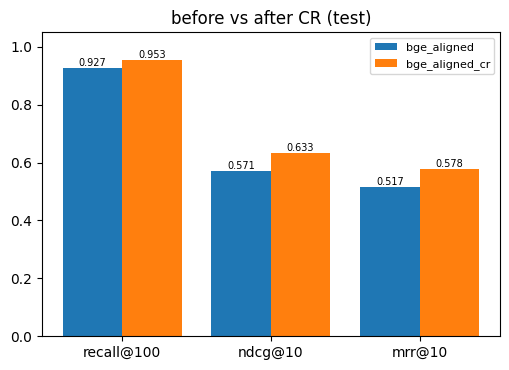

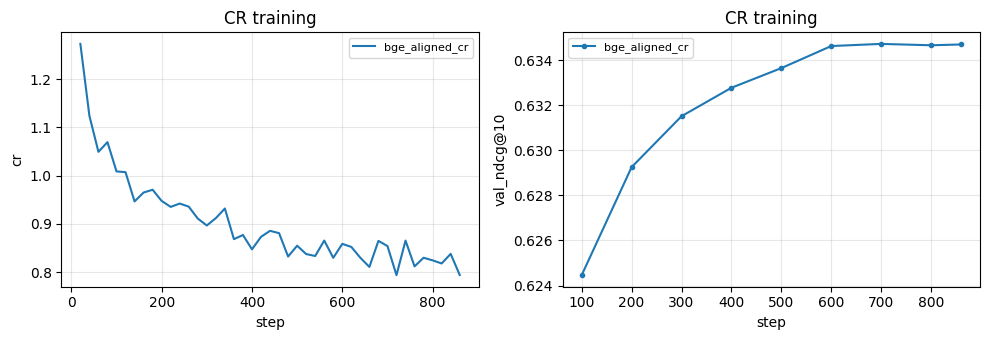

In [6]:
import matplotlib.pyplot as plt
from IPython.display import display
from run_exp import exp_cr

res = exp_cr(REFINE, runs, data, index, RUN_DIR, EVAL, NPROCS)
runs["bge_aligned_cr"] = f"{RUN_DIR}/bge_aligned_cr/final"
for fig in res["figs"]:
    display(fig)
plt.close("all")

## 4 · Training curves
`val_loss` is L2 in both stages (comparable); `train_loss` is L2 in stage 1, CR + l2_weight · L2 in stage 2.

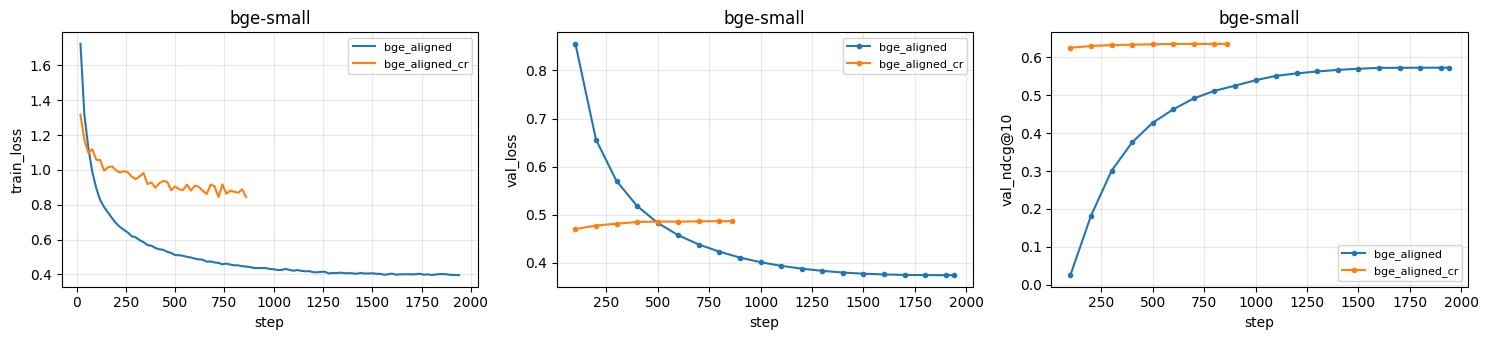

In [7]:
from run_exp import plot_curves, save_fig

fig = plot_curves({n: f"{RUN_DIR}/{n}" for n in runs}, ("train_loss", "val_loss", "val_ndcg@10"), "bge-small")
display(save_fig(fig, RUN_DIR, "bge_small_curves"))
plt.close("all")

## 5 · Retrieval quality (val + test)
Student queries vs the frozen teacher corpus. retention = nDCG@10 / teacher nDCG@10.

In [8]:
from run_exp import print_rows

metrics = load_json(f"{RUN_DIR}/metrics.json")
for split in ("val", "test"):
    print_rows(metrics, list(runs), split)
    print()

split=val
run                    recall@100  recall@10    ndcg@10     mrr@10  retention
teacher                    0.9937     0.9405     0.8015     0.7591     1.0000
bge_aligned                0.9325     0.7556     0.5722     0.5184     0.7139
bge_aligned_cr             0.9541     0.8240     0.6347     0.5782     0.7919

split=test
run                    recall@100  recall@10    ndcg@10     mrr@10  retention
teacher                    0.9928     0.9457     0.8063     0.7639     1.0000
bge_aligned                0.9266     0.7572     0.5714     0.5166     0.7087
bge_aligned_cr             0.9532     0.8171     0.6327     0.5783     0.7848



## 6 · Query latency (one GPU, fp16)

In [9]:
from evaluation import measure_latency
from model import load_encoder
from teacher import free_gpu_memory

texts = data["val"]["texts"][:LATENCY["n_queries"]]
for name, path in runs.items():
    model, tok = load_encoder(path, EVAL["device"], torch.float16)
    print(f"--- {name}: {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M params")
    measure_latency(model, tok, texts, EVAL["device"], T["dim"], 32, QUERY_PREFIX, LATENCY["batch_sizes"])
    del model
    free_gpu_memory()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

--- bge_aligned: 33M params
[latency] bs=1       8.019 ms/query       124.7 q/s
[latency] bs=32      0.353 ms/query      2830.5 q/s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

--- bge_aligned_cr: 33M params
[latency] bs=1       8.099 ms/query       123.5 q/s
[latency] bs=32      0.357 ms/query      2805.0 q/s
